# resonator_chip_01 — chip_01's five λ/4 resonators without the qubits (legacy QWri), on the Quantcore PDK

## 1 · What the chip is

**Source:** `components/python/resonator_chip_01.py` (`create_chip`, output `res_01.gds`), Quantcore internal.
Spec: `docs/designs/legacy/resonator_chip_01.md`.

The resonator-only twin of chip_01: a 10/6 µm feedline between two rounded bond pads and five `Coupled
Resonator`s (cpw_len 5000 µm, 300 µm couplers at 2 µm, necks 600 … 300 µm), alternating above and below the
line. Labels "RES" and "1" … "5". No frequency targets in the source.

| | the rebuild keeps (source-faithful) | the Quantcore PDK changes |
|---|---|---|
| resonators | the five `Coupled Resonator`s with the legacy parameters, own open ends (no grounder boxes) | — |
| feedline, pads | rounded "Connector Pad" geometry (`ConnectorPad`, fab drawing), 10/6 µm CPW (`CpwSegment`) | pads with their outer etch **`pad_edge` = 100 µm** from the die edge (the design-area margin, where an earlier decision had already put them): feedline 5950 (legacy) → 5260 µm |
| cheese | — (the source has none) | the **PDK band** (3 rows of 5 µm squares, 20 µm gaps, around the 3/0 keep-outs; `cheese: "auto"`) |
| placement | everything relative to the feedline | the circuit **centred in the die** (it sat 155 µm high: the three resonators above are longer than the two below) |
| frame | — | the PDK die frame and device ID `RES01` |
| junctions | — (no qubits) | — |

**Reproduced exactly** (XOR 0 against the author's own PCells, read-only through `tests/legacy_ref`, step 14): the
five resonators and the labels; the pads and feedline at the PDK pad position.

### Changes after design review (2026-11-03)

- **#13 grounder boxes — removed.** The legacy script etched a 22 × 10 µm box where chip_01's claws sit, meant to
  ground (terminate) the resonator end; on R1, R4 and R5 it cut the tail 318 / 119 / 14 µm short (leaving floating
  stubs), on R2 and R3 it missed the line. The user: not intended — the later PCell decides which end is shorted and
  which is open. Each resonator now ends with the `Coupled Resonator`'s own open end (`ground=True`: gap cap at the
  far end, shorted at the coupler): full 5000 µm λ/4s, no cut, no floating stub.
- **#9 pads outside the die — repositioned.** At the legacy tips (∓2975, 0) the rounded pads ended 245 µm outside the
  7.5 mm die (laid out for a smaller die). They now sit 345 µm further in (tips ∓2630, feedline 5950 → 5260 µm), so the
  rounded end lies on the design-area edge, 100 µm inside the die, clear of the dicing lane and the corner markers;
  the feedline still spans all five couplers. Same as chips 01, 01_creator and 02.
- **Consequence:** with the cuts gone the five resonators are identical (5000 µm, same coupler), so they share one
  frequency (≈ 6.37 GHz loaded) — degenerate on one feedline. The legacy source gives no other lengths; if they should
  be spread (e.g. like chip_02's 5050 … 4000 µm), that is a design decision.
- **Not re-executed here** (verification policy for this pass): the saved JSON is rebuilt from the layout
  cell, the outputs are cleared; run the notebook to regenerate the tables and PNGs.

### PDK conformance pass (notebooks-legacy, 2026-11-03; pad rule 100 µm, 2026-11-10)

- **Pads:** the PDK pad rule (outer etch `get_pdk().frame.pad_edge` = 100 µm from the die edge) is placed with
  `edge="auto"` on the left pad; the feedline snaps onto it with the length the rule leaves (5260 µm), the right pad
  snaps onto its far end. With the 100 µm rule this is exactly #9's design-area edge (pads 345 µm in from the legacy
  tips); with the earlier 25 µm rule it was 5410 µm. DRC `pad_edge` warnings: 2 → 0.
- **Centring:** the circuit sat 155 µm above the die centre; `L.center_circuit` moves everything down by 154.5 µm
  (labels with it; the "RES" label near the top edge is not part of the measure).
- **Cheese:** the source has none, so the PDK band applies (`cheese: "auto"`), drawn by the build and kept by the
  fab export (8126 holes).
- Educative layout: one step per stage (die → pads and feedline → resonators → labels and centring → DRC → LOM →
  FEM → iterate → export → snapshots).

## 2 · Setup and the Quantcore PDK

The helpers keep the cells short: `_common` (`C`) holds the netlist / LOM / FEM-export / snapshot helpers and
the PDK checks shared by every design notebook; `_legacy` (`L`) maps the legacy PCell parameters onto the
Quantcore cells, draws the legacy reference with the author's own legacy code (read-only), and holds the step
helpers of these notebooks. `LIVE` decides whether the design is pushed to a running KLayout (`QCC_LIVE=0`
for batch runs: nothing reaches KLayout).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                       # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
sys.path.insert(0, str(ROOT / "examples" / "designs" / "legacy"))
LIVE = os.environ.get("QCC_LIVE", "1") == "1"       # live KLayout by default; QCC_LIVE=0 for batch runs
import _common as C                                  # netlist / LOM / FEM-export / snapshot / PDK-check helpers
import _legacy as L                                  # legacy frame shift, parameter mapping, legacy reference, steps
import _legacy_b as LB                               # resonator_chip_01 tables and legacy reference
from IPython.display import Image, Markdown, display
from quantcore_circuits.designer import Designer
from quantcore_circuits.pdk import get_pdk

ID, OUT = "resonator_chip_01", Path("examples/designs/legacy")

The PDK facts this rebuild uses, read from `get_pdk()` (nothing below is typed in by hand). The rules that
change a legacy chip are the **pad rule** (step 4), the **junction rule** (step 5), the **3/0 keep-out**
and the **cheese rule** (drawn by the build, step 13) and the centring of the content (step 6).

In [3]:
CHEESE_NOTE = 'PDK band (auto) — the source has no cheese of its own'
display(Markdown(L.pdk_facts_md(CHEESE_NOTE)))

| PDK item | value |
|---|---|
| PDK | `quantcore_nb_sapphire_v1` (version 3) |
| stack | sapphire, 650 µm, ε_r 10.25; Nb film (sheet metal in the FEM exports, 0.2 µm for the analytic CPW formulas) |
| CPW default | 10 µm centre, 6 µm gap, bends r = 100 µm |
| die frame | L-shaped dicing markers 25 µm wide (250 µm legs, 1000/0), 3 × 3 alignment grids (1001/0) in 500 µm corner squares, design area 100 µm inside the die edge, device ID optional (bottom centre, or beside the pads) |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (the design-area margin) from the die edge, whatever the original did (`edge="auto"`, DRC design warning `pad_edge`) |
| junction rule | Nb/AlOx/Nb trilayer, Δ = 1.4 meV (I_c·R_n = πΔ/2e), R_n 40–50 kΩ (nominal 45), qubits 4–8 GHz; R_n·A 13500 Ω·µm² and C_J 50 fF/µm² assumed; cells `Quantcore Junction` / `Quantcore Squid` (DRC design warnings `pdk_rn`, `pdk_fq`: flagged, never retuned) |
| 3/0 keep-out | second-metal etch: routes + 10 µm, components' etch bbox + 24 µm, other 1/0 shapes + 9 µm (filled) |
| cheese rule | 3 rows of 5 µm squares, 20 µm gaps, in a band around the 3/0 keep-outs; **the original design's own cheese wins** (chip `cheese`: `"auto"` / `"pdk"` / `"original"`). This chip: PDK band (auto) — the source has no cheese of its own |

## 3 · The die and the frame

`Designer(ID, box=...)` starts an empty 7.5 × 7.5 mm die. The PDK frame is drawn on every build: four L-shaped
dicing markers (1000/0), the 3 × 3 alignment grids (1001/0), the chip boundary (100/0) and the device ID `RES01`
at the bottom centre. The chip parameter `cheese` is left at `"auto"`: the source has no cheese, so the build
draws the PDK band (visible from step 5 on). Legacy coordinates are centred on (0, 0); `L.at` / `L.place` shift
them by (+3750, +3750) µm into the Designer frame.

(0.0, 0.0, 7500.0, 7500.0) quantcore_nb_sapphire_v1


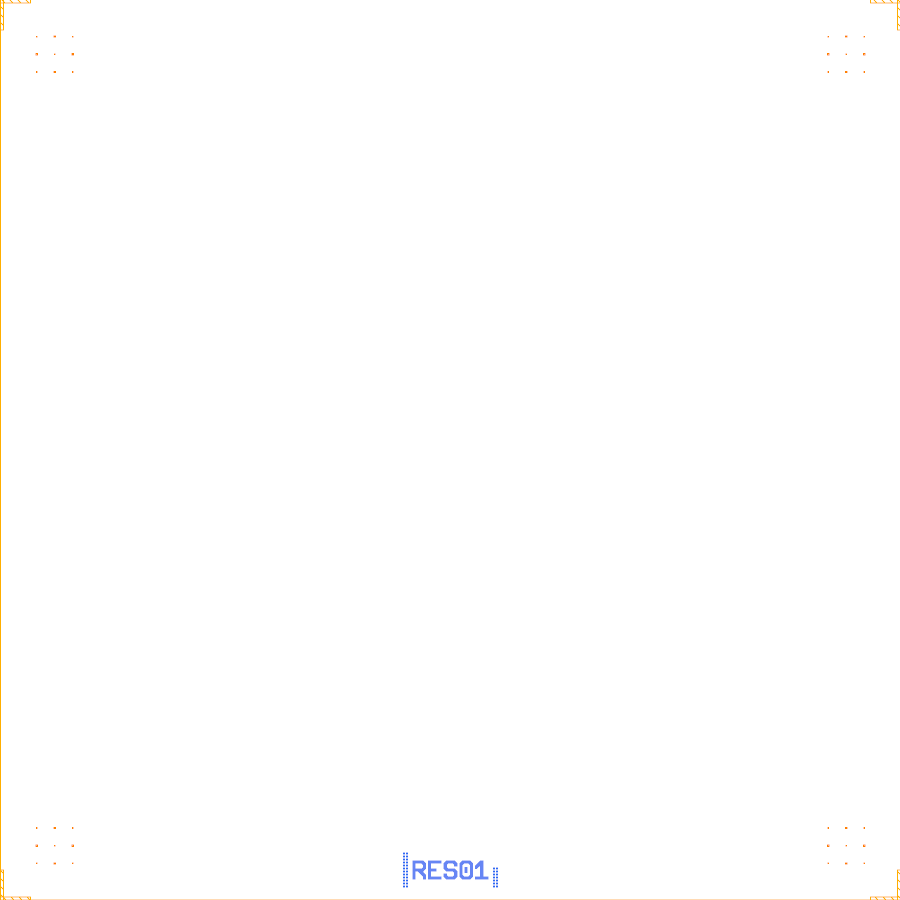

WindowsPath('build/legacy_steps/resonator_chip_01_1_frame.png')

In [4]:
d = Designer(ID, box=(0, 0, L.W, L.H), chip={"name_chip": "RES01"}, live=LIVE)    # cheese: "auto" (PDK band)
print(d.design.chip.box, d.design.pdk)
L.step_snapshot(d, "1_frame")

## 4 · Pads (PDK pad rule) and the feedline

The rounded legacy "Connector Pad" (`ConnectorPad`: 275 × 300 µm pad, 300 µm taper, fab drawing) goes at the
left end of the feedline with the legacy rotation (rot 3); `edge="auto"` slides it perpendicular to its nearest
die edge until the outer edge of its etch is **`pad_edge` = 100 µm** (`get_pdk().frame.pad_edge`, the design-area margin)
from the die edge. The legacy pads ended 245 µm *outside* the die; the design decision had moved them to the
design-area edge (100 µm in); the PDK pad rule (100 µm since 2026-11-10) puts them at the same place, now measured from the build instead of hard-coded.

The feedline (`CpwSegment`, 10/6 µm) snaps onto the left pad's port with the length the rule leaves on a
symmetric chip, and the right pad snaps onto its far end, as in the source (pads snapped to the feedline ends:
one conductor in the netlist). It still spans all five couplers (x = −2150 … +2150 legacy).

pad etch → die edge (µm): {'PL': 100.0, 'PR': 100.0}
feedline 5260 µm (legacy 5950 µm; pads 345 µm in from the legacy tips)


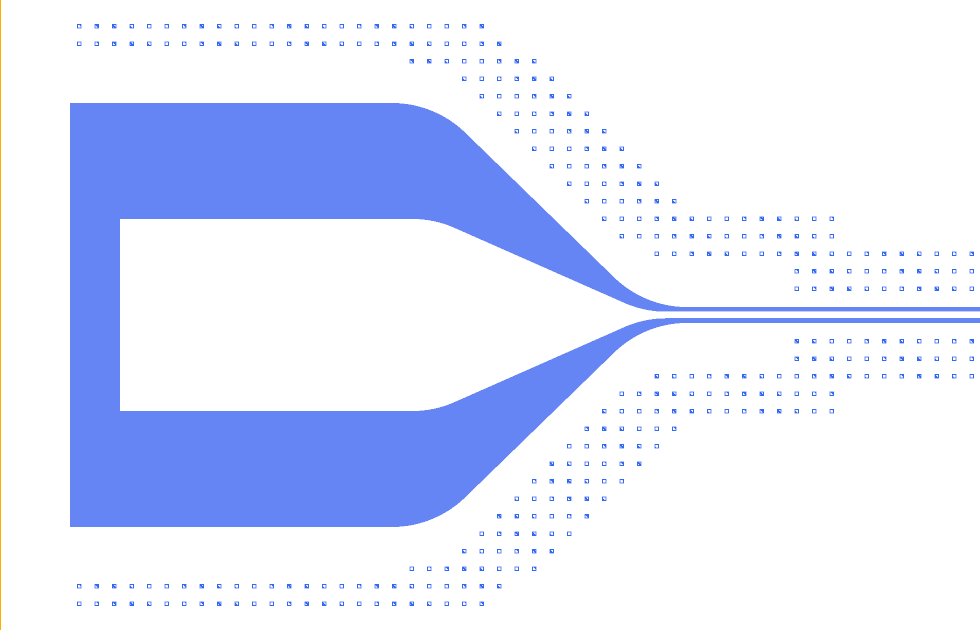

WindowsPath('build/legacy_steps/resonator_chip_01_2_pads.png')

In [5]:
PAD = L.connector_pad(**LB.RC1_PAD)                                           # legacy "Connector Pad", rounded
d.add("PL", "ConnectorPad", **L.place(-2700, 0, 3), edge="auto", **PAD)        # legacy (−2975, 0), rot 3
x_a = C.port_xy(d, "PL.a")[0]
FEED = LB.RC1_FEED | {"length": round(L.W - 2 * x_a, 3)}                       # symmetric chip
PAD_SHIFT = LB.RC1_FEED["length"] / 2 - FEED["length"] / 2                     # pads moved in from the legacy tips
with d.batch():
    d.add("FL", "CpwSegment", snap="a", to="PL.a", **L.cpw_segment(**FEED))
    d.add("PR", "ConnectorPad", snap="a", to="FL.b", **PAD)                     # legacy (+2975, 0), rot 1
print("pad etch → die edge (µm):", L.edge_gaps(d))
print(f"feedline {FEED['length']:.0f} µm (legacy {LB.RC1_FEED['length']} µm; pads {PAD_SHIFT:g} µm in from the legacy tips)")
L.step_snapshot(d, "2_pads", box=(0, 3300, 1400, 4200), size=(980, 630), width=490)

## 5 · Components: the five λ/4 resonators

Each `CoupledResonator` is the legacy `Coupled Resonator` PCell (`L.coupled_resonator`): a meandered 10/6 µm
λ/4 of 5000 µm, shorted at the end of a 300 µm coupler beside the feedline behind a 2 µm ground strip, with the
PCell's own open end (`ground=True`, gap cap; the legacy "grounder" boxes are not drawn). The necks
(600 … 300 µm) only move the meander away from the line. `d.couple("K_Rn", "Rn", "FL")` declares the coupler
∥ feedline coupling, which becomes a hanger κ in the netlist. The PDK cheese band appears around everything in
the snapshot (the build draws it).

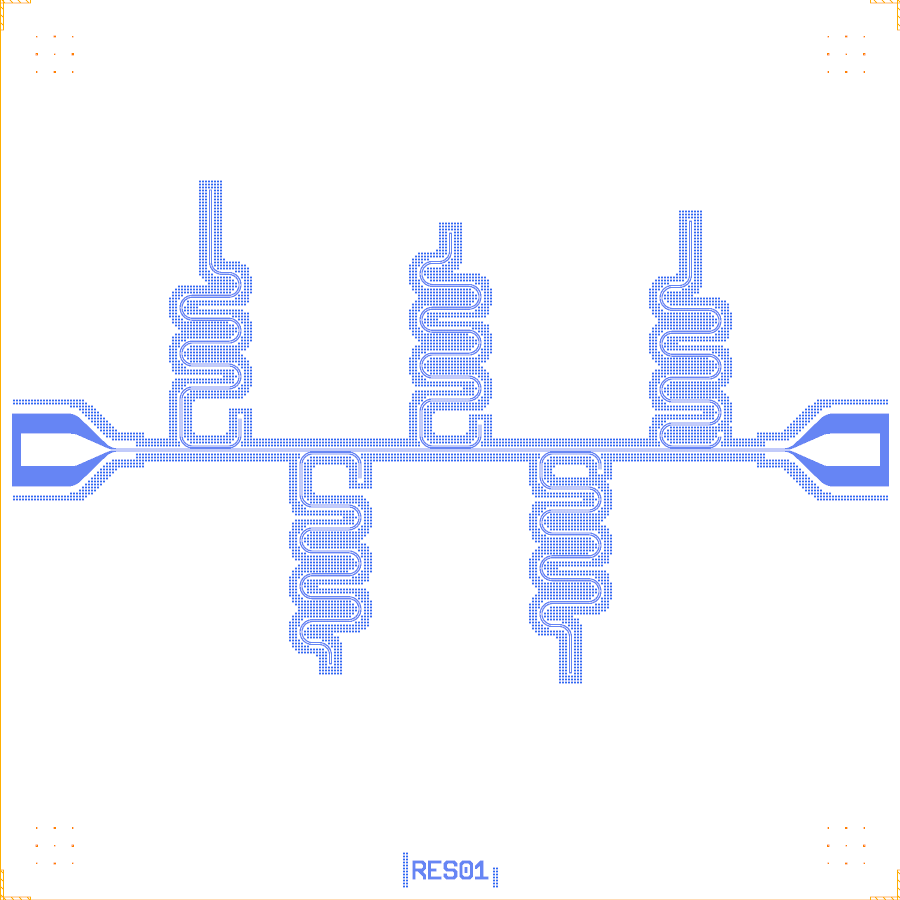

WindowsPath('build/legacy_steps/resonator_chip_01_3_resonators.png')

In [6]:
with d.batch():
    for n, (x, y, mirror, neck, _v) in LB.RC1_RES.items():
        d.add(n, "CoupledResonator", **L.place(x, y, 0, mirror),          # ground=True: the PCell's own open end
              **L.coupled_resonator(**LB.RC1_RES_COMMON | {"neck_length": neck, "ground": True}))
        d.couple(f"K_{n}", n, "FL", note="300 µm coupler parallel to the feedline, 2 µm ground strip")
L.step_snapshot(d, "3_resonators")

## 6 · Labels and centring

The labels "RES" and "1" … "5" (`TextLabel`, the legacy `TextGenerator` font). No routes: like the legacy chip,
it is drawn from fixed cells whose ports touch. Then the **PDK placement rule**: `L.center_circuit` measures the
circuit (instances and routes; the free text labels are excluded from the measure because the source places
"RES" near the top die edge, but they move with everything) and shifts the design so it sits in the middle of
the die. Then the design is saved: the JSON is what every later step reads.

centring shift (µm): (0.0, -154.5) | feedline y = 3595.5 | <Designer resonator_chip_01: 14 instances, 0 routes, live=False> → examples\designs\legacy\resonator_chip_01.json


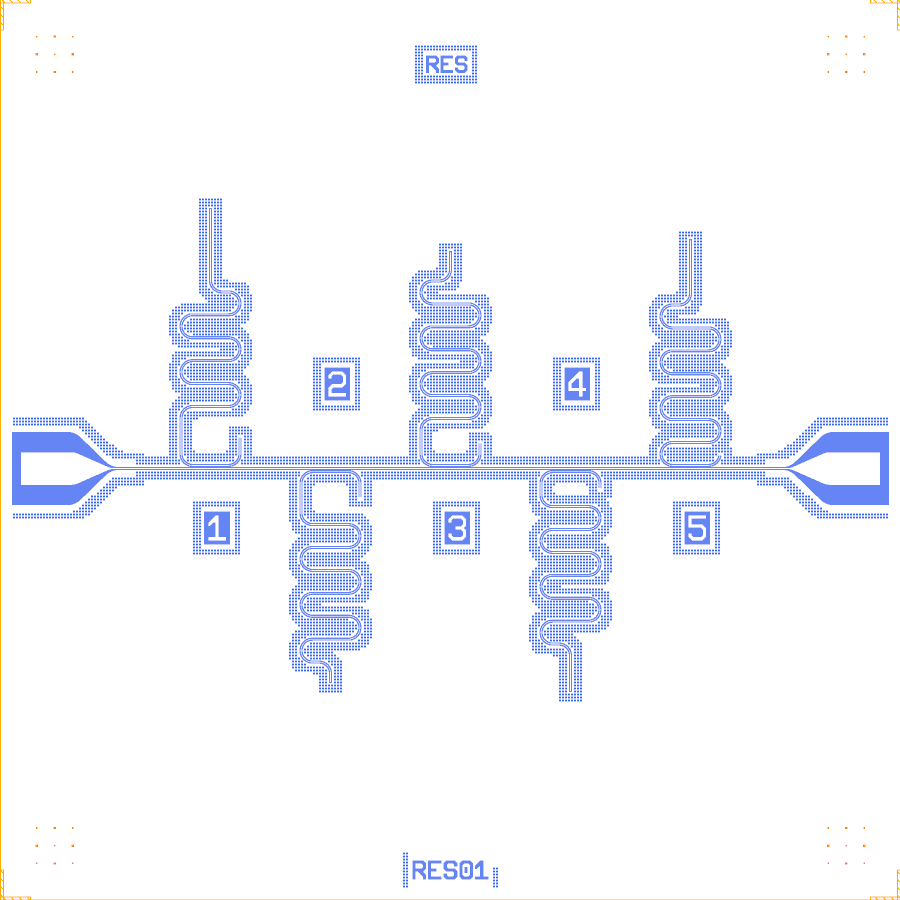

WindowsPath('build/legacy_steps/resonator_chip_01_4_centred.png')

In [7]:
with d.batch():
    for name, text, mag, inv, x, y, rot in LB.RC1_TEXT:
        d.add(name, "TextLabel", **L.place(x, y, rot), text=text, mag=mag, inverted=inv)
for n in LB.RC1_RES:                       # FEM groups: each resonator with the feedline (+ its pads, added by the export)
    d.sim_group(n, [n, "FL"], margin_um=300, analyses=["q3d_cmatrix", "eigenmode_epr"])
SHIFT = L.center_circuit(d)
DESIGN = d.save(OUT / f"{ID}.json")
print("centring shift (µm):", SHIFT, "| feedline y =", round(C.port_xy(d, "FL.a")[1], 1), "|", d, "→", DESIGN)
L.step_snapshot(d, "4_centred")

## 7 · DRC

`d.drc()` builds the chip and checks it: **errors** (overlapping etch of unrelated cells, ports not landing,
parts outside the chip) must be fixed; **warnings** are reported for a person to judge (a dangling open end,
two cells' bounding boxes touching); **PDK design warnings** (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`) flag
values outside the PDK margins — they are never retuned for, only listed. `C.pdk_report(d)` summarises the
PDK checks: cheese source, content centring, junction types and the design warnings.

Expected: zero errors; `dangling_port` on the five resonator `end`s (open ends with gap caps: nothing connects
there by design). No PDK design warnings (no `pad_edge` any more, no junctions). `pdk_report`: cheese "PDK band",
content centre (+0, +0) µm (free text labels such as "RES" are left out of the measure).

In [8]:
drc = d.drc()
print(drc)
display(Markdown(C.pdk_report(d)))

warning dangling_port R1.end is not connected (no route or snap)
warning dangling_port R2.end is not connected (no route or snap)
warning dangling_port R3.end is not connected (no route or snap)
warning dangling_port R4.end is not connected (no route or snap)
warning dangling_port R5.end is not connected (no route or snap)


| check | value |
|---|---|
| cheese | PDK band (drawn in the build) |
| content centre − die centre | (+0, +0) µm |
| junction types | — |
| PDK design warnings | 0 (none) |

## 8 · Netlist and LOM

`d.lom()` turns the layout into a lumped-element circuit: the feedline and both pads are one node with a 50 Ω
port at each pad; each resonator is a λ/4 `TLres` (full drawn length, shorted at its coupler, open at its gap
cap) with a `HANGER` κ element to the feedline (from the 300 µm coupler and the 2 µm strip).

In [9]:
lb = d.lom()
C.show_netlist(lb)
print(C.lom_summary(lb))

**7 nodes · 12 branches · 0 controls · 5 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `FL.line` | `PL.pad`, `FL.line`, `PR.pad` |
| `R1.res` | `R1.res` |
| `R2.res` | `R2.res` |
| `R3.res` | `R3.res` |
| `R4.res` | `R4.res` |
| `R5.res` | `R5.res` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Port_PL` | R | `FL.line` – `gnd` | 50 Ω |
| `Port_PR` | R | `FL.line` – `gnd` | 50 Ω |
| `R1` | TLres | `R1.res` – `gnd` | lambda/4, 5000 µm, 6.302 GHz |
| `K_R1` | HANGER | `R1.res` – `FL.line` | κ 0.348 MHz (L 300 µm) |
| `R2` | TLres | `R2.res` – `gnd` | lambda/4, 5000 µm, 6.302 GHz |
| `K_R2` | HANGER | `R2.res` – `FL.line` | κ 0.348 MHz (L 300 µm) |
| `R3` | TLres | `R3.res` – `gnd` | lambda/4, 5000 µm, 6.302 GHz |
| `K_R3` | HANGER | `R3.res` – `FL.line` | κ 0.348 MHz (L 300 µm) |
| `R4` | TLres | `R4.res` – `gnd` | lambda/4, 5000 µm, 6.302 GHz |
| `K_R4` | HANGER | `R4.res` – `FL.line` | κ 0.348 MHz (L 300 µm) |
| `R5` | TLres | `R5.res` – `gnd` | lambda/4, 5000 µm, 6.302 GHz |
| `K_R5` | HANGER | `R5.res` – `FL.line` | κ 0.348 MHz (L 300 µm) |

**Unconnected ports:** `R1.end`, `R2.end`, `R3.end`, `R4.end`, `R5.end`

{'nodes': 6, 'branches': 12, 'controls': 0, 'unconnected': 5}


## 9 · LOM simulation

Each resonator with the feedline and its pads (QuCat normal mode and κ, QuTiP-dressed f_r; `C.simulate_groups`
runs one small sub-circuit per resonator).

In [10]:
results = C.simulate_groups(d, {n: [n, "FL", "PL", "PR"] for n in LB.RC1_RES})
display(Markdown(C.groups_md(results)))

| group | qubit | f_q (GHz) | α (MHz) | resonator | f_r (GHz) | κ (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|---|
| R1 | – | – | – | R1 | 6.2629 | 0.339 | – |
| R2 | – | – | – | R2 | 6.2629 | 0.339 | – |
| R3 | – | – | – | R3 | 6.2629 | 0.339 | – |
| R4 | – | – | – | R4 | 6.2629 | 0.339 | – |
| R5 | – | – | – | R5 | 6.2629 | 0.339 | – |

**Reading the numbers** (LOM of this run). All five resonators are 5000 µm long with identical couplers, so the
LOM puts them all at the same frequency (≈ 6.26 GHz loaded, κ ≈ 0.34 MHz each): degenerate on one feedline (see
the changes). The earlier spread (R1 6.80, R4 6.52, R5 6.38 GHz) came only from the unintended grounder cuts
(#13).

## 10 · FEM: send the job

Each sim group is cut out of the chip (its instances plus a margin of ground), with the PDK stack (sapphire
650 µm, ε_r 10.25) and **without cheese** (simulation exports never have it), and written as a job folder
under `build/jobs/` (`C.export_sims` → `build_simulation` + `export_job`): a Q3D C-matrix job by default,
`analysis="eigenmode_epr"` for the eigenmode / EPR job. With `RUN_FEM = True` and AEDT 2024 R1 (v241) or
newer on this machine, `L.fem_send` solves each job in a **new batch, non-graphical** AEDT
(`sim_tools.hfss.solve_job`) — it never touches an AEDT window you have open. The default here is
`False`: export only.

Here: one Q3D C-matrix job per resonator with the feedline. The connector pads that terminate the feedline (`PL`,
`PR`) join each group with their 50 Ω lumped ports, so the feedline is never floating. Each λ/4 resonator is
shorted to ground at its coupler end, so its centre conductor is part of ground: the only C-matrix net is the
feedline (named after the first pad port on it), and the hanger coupling shows up as the eigenmode Q (κ) of the
loaded resonator (`analysis="eigenmode_epr"`).

In [11]:
RUN_FEM = False                       # True: solve the exported jobs here (AEDT 2024 R1+, batch)
jobs = C.export_sims(DESIGN)
display(Markdown(C.jobs_md(jobs)))
display(Markdown(L.fem_send(jobs, run=RUN_FEM)))

| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| R1 | `build/jobs/resonator_chip_01_R1_q3d_cmatrix` | 1 · lumped · `PL.pad`<br>2 · lumped · `PR.pad` | `PL.pad`, `floating1`, `floating2`, `floating3`, `floating4`, `floating5` |
| R2 | `build/jobs/resonator_chip_01_R2_q3d_cmatrix` | 1 · lumped · `PL.pad`<br>2 · lumped · `PR.pad` | `PL.pad`, `floating1`, `floating2`, `floating3` |
| R3 | `build/jobs/resonator_chip_01_R3_q3d_cmatrix` | 1 · lumped · `PL.pad`<br>2 · lumped · `PR.pad` | `PL.pad`, `floating1`, `floating2`, `floating3`, `floating4`, `floating5` |
| R4 | `build/jobs/resonator_chip_01_R4_q3d_cmatrix` | 1 · lumped · `PL.pad`<br>2 · lumped · `PR.pad` | `PL.pad`, `floating1`, `floating2`, `floating3` |
| R5 | `build/jobs/resonator_chip_01_R5_q3d_cmatrix` | 1 · lumped · `PL.pad`<br>2 · lumped · `PR.pad` | `PL.pad`, `floating1`, `floating2`, `floating3`, `floating4`, `floating5` |

AEDT on this machine: `C:\Program Files\AnsysEM\v241\Win64\ansysedt.exe` (v241)

`RUN_FEM = False`: 5 job(s) exported, none solved. Set `RUN_FEM = True` to solve them here (batch, non-graphical), or run `qcc sim run <job>` on a machine with AEDT 2024 R1+.

## 11 · Bring the results back

A solved job leaves `results/results.json` in its folder. `fill(model, DESIGN, job)` then replaces the LOM's
component estimates by the FEM C-matrix, matched by net name (the net names are the ones in the job table
above), and the LOM is simulated again with them. `L.fem_bring_back` does this for every job that has
results and says which have none yet.

No job has been solved yet, so the cell says so; with eigenmode results the loaded f_r and Q of each resonator
would appear next to the LOM's.

In [12]:
display(Markdown(L.fem_bring_back(d, DESIGN, jobs, groups=None)))

No FEM results yet for 5 job(s) (`build/jobs/resonator_chip_01_R1_q3d_cmatrix`, `build/jobs/resonator_chip_01_R2_q3d_cmatrix`, `build/jobs/resonator_chip_01_R3_q3d_cmatrix`, `build/jobs/resonator_chip_01_R4_q3d_cmatrix`, …). After a solve each job holds `results/results.json`; this cell then fills the LOM with the extracted C-matrix (`fill(model, DESIGN, job)`) and shows the estimate next to the FEM value per capacitance, and f_q / α / f_r / χ re-simulated with them.

## 12 · Iterate: change one property and re-simulate

The five resonators are degenerate (all 5000 µm). A variant that would separate them: shorten R5 by 300 µm
(`cpw_len` 4700): f_r rises by about 6 %, so R5 leaves the common frequency. The copy is not saved — the chip
keeps the legacy lengths (spreading them is a design decision).

In [13]:
d2 = Designer.load(DESIGN, live=False, verbose=False)      # a copy of the saved design
d2["R5"].set(cpw_len=4700)
after = C.simulate_groups(d2, {"R5": ["R5", "FL", "PL", "PR"]})["R5"]
display(Markdown(L.compare_md(results["R5"], after, keys=["R5.f_GHz", "R5.kappa_MHz"],
                              label=("cpw_len 5000 µm", "cpw_len 4700 µm"))))

| parameter | cpw_len 5000 µm | cpw_len 4700 µm | Δ |
|---|---|---|---|
| `R5.f_GHz` | 6.2629 | 6.6601 | +0.3972 |
| `R5.kappa_MHz` | 0.33909 | 0.40745 | +0.06837 |

## 13 · Build and export

The design is saved as JSON (`DESIGN`, step 6): it is the source of truth — the layout, the netlist, the
FEM jobs and the mask are all made from it. The **fab mask** (`export_fab`) keeps only the PDK fab layers
(1/0 etch, 2/0 + 4/0 junction fingers, 3/0 second-metal keep-out, 50–53/0 spacer, 100/0 boundary, 1000/0 +
1001/0 markers), rounds the corners (radius ∝ each polygon's shortest dimension) and keeps the build's
cheese. **Simulation exports** never carry cheese; they drop airbridges unless asked
(`build_simulation(..., airbridges=True)`); the legacy chips have none.

Here: `cheese=True` (the default): the build already carries the PDK band (the source has no cheese), so the
mask keeps it (`cheese_source` "build").

The same from a shell:

```
qcc build examples/designs/legacy/resonator_chip_01.json                    # layout → build/resonator_chip_01.oas
qcc mask  examples/designs/legacy/resonator_chip_01.json          # fab mask with the PDK rules
qcc sim build examples/designs/legacy/resonator_chip_01.json -g R1 -a q3d_cmatrix   # one FEM job (step 10)
qcc sim run build/jobs/resonator_chip_01_R1_q3d_cmatrix              # solve it (AEDT 2024 R1+)
```

In [14]:
display(Markdown(L.fab_md(d, cheese=True)))

Fab mask: `build/resonator_chip_01_fab.oas` · cheese source **build** (8126 PDK-band holes) · corner rounding on

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 8147 |
| 3/0 | M3 | 8138 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

## 14 · Snapshots and comparison with the legacy geometry

The full chip; zooms on R1's open end (where the grounder box used to cut it, with the PDK cheese band around it)
and on R1's coupler; then the legacy chip drawn by the author's own PCells (read-only harness, moved by the
centring shift) and the per-instance XOR on 1/0 — against the legacy as drawn (pads at the legacy tips,
grounder boxes: PL/PR/FL and R1/R4/R5 differ by the changes), then the intended chip (pads moved in as here, no
grounders). Expected: 0 on every instance of the intended chip. The rebuild's cheese is on its own layer
(`ground_grid`), not part of the 1/0 compared here.

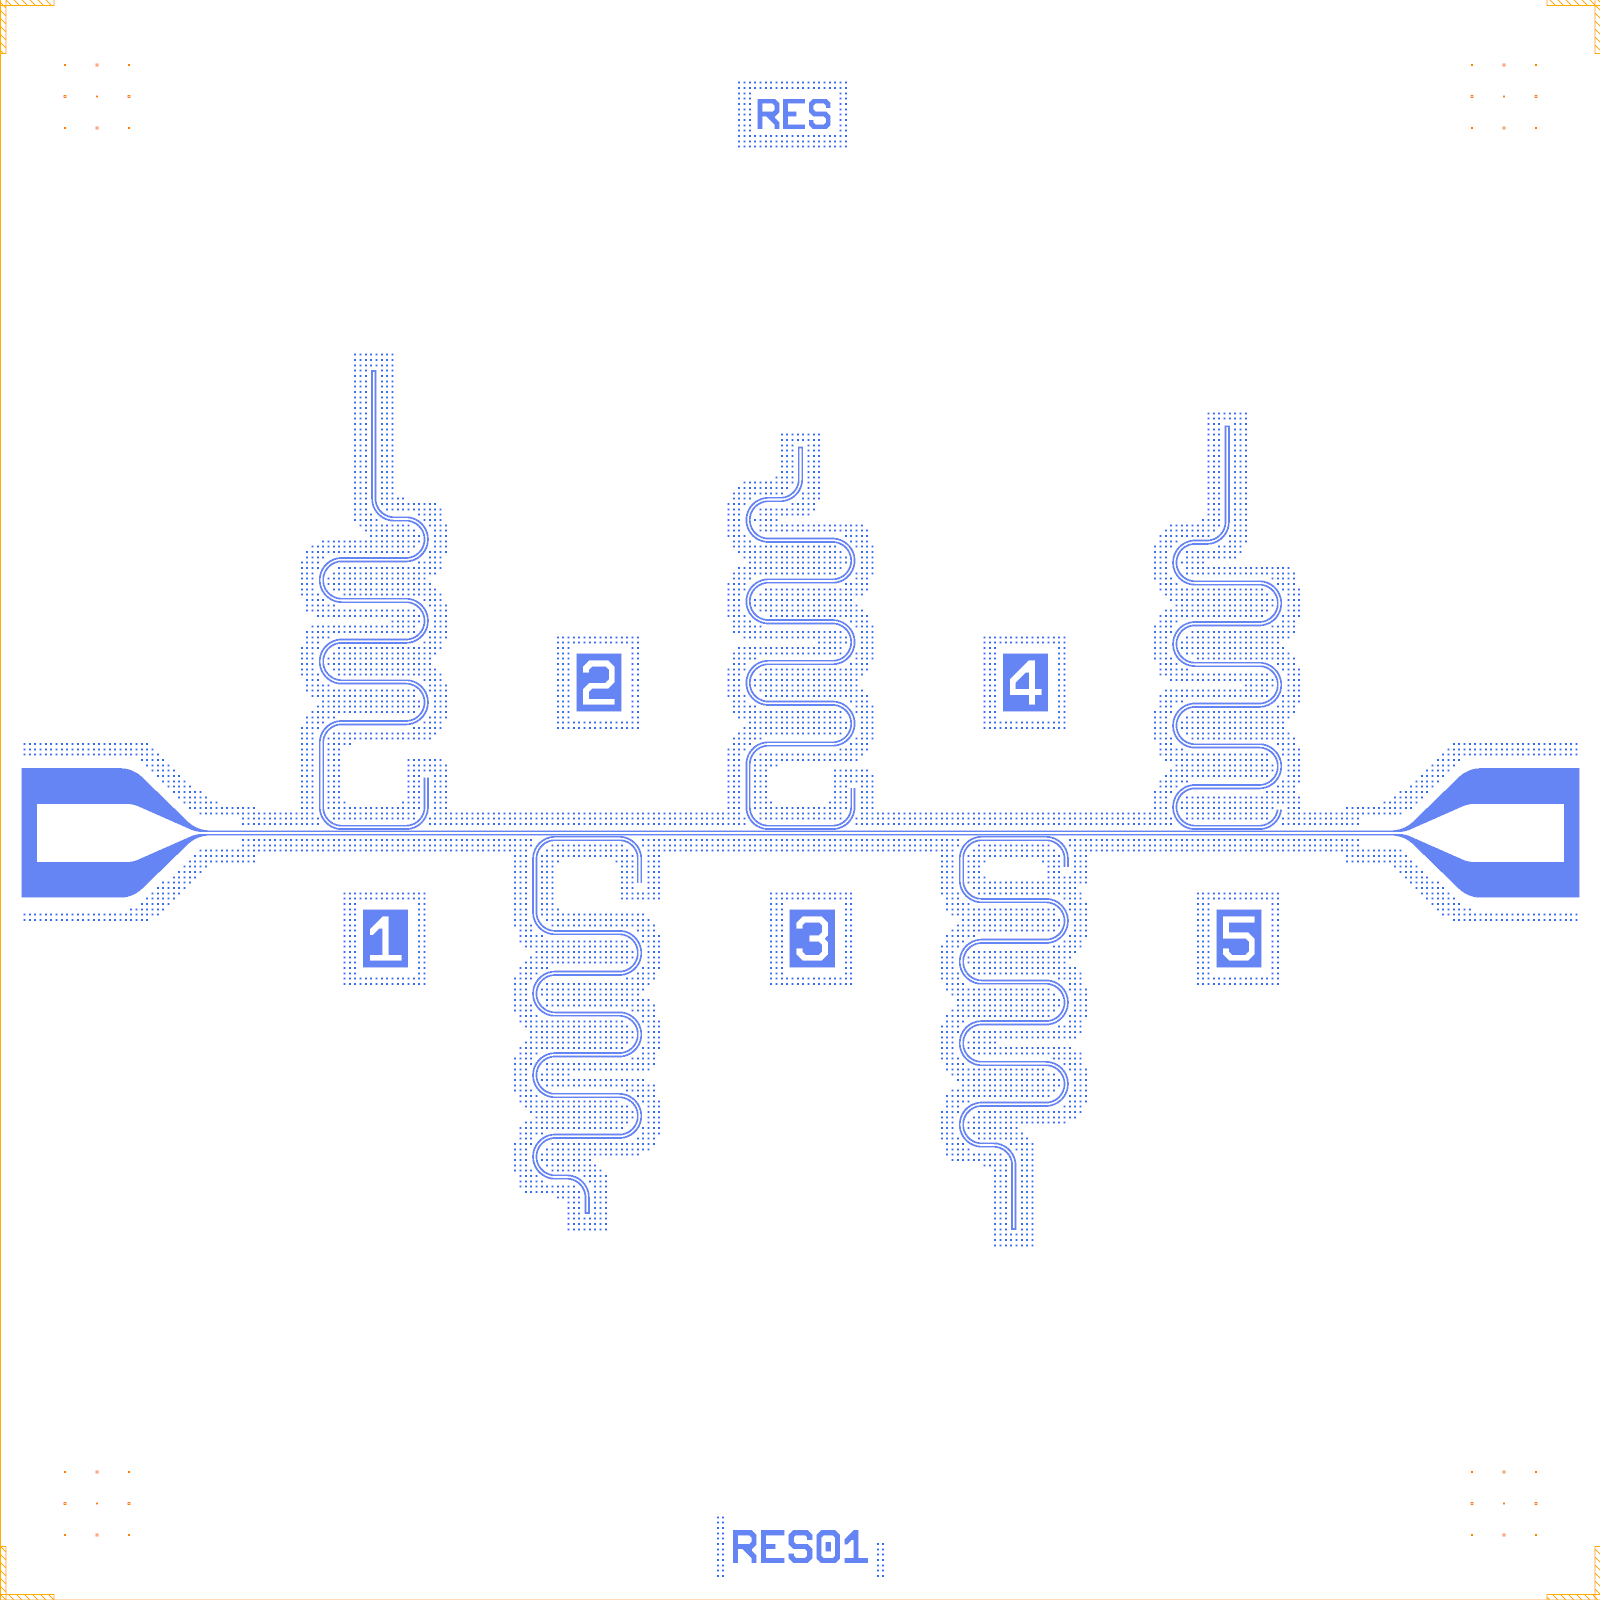

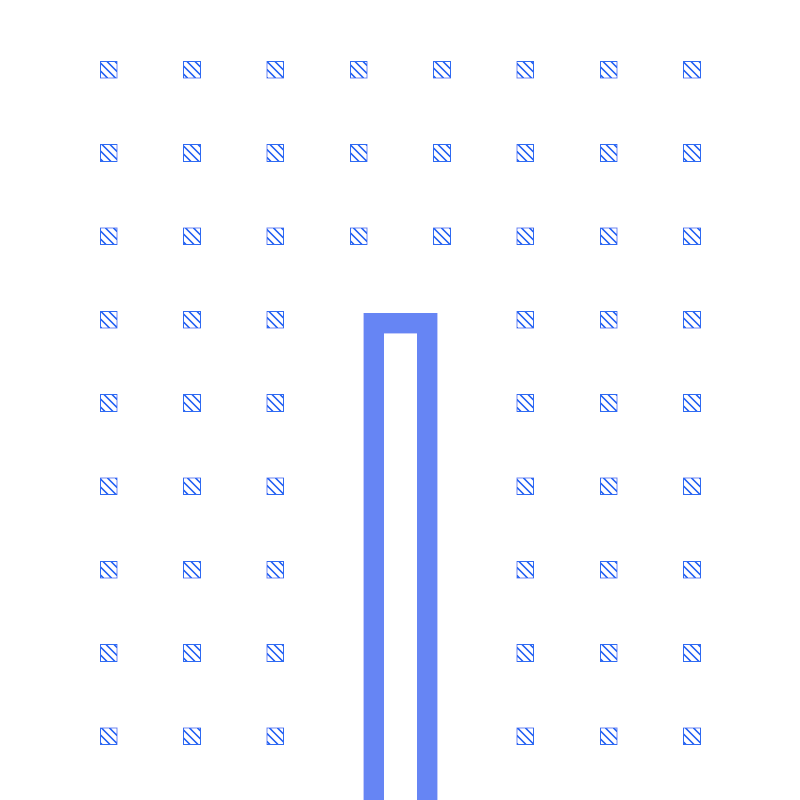

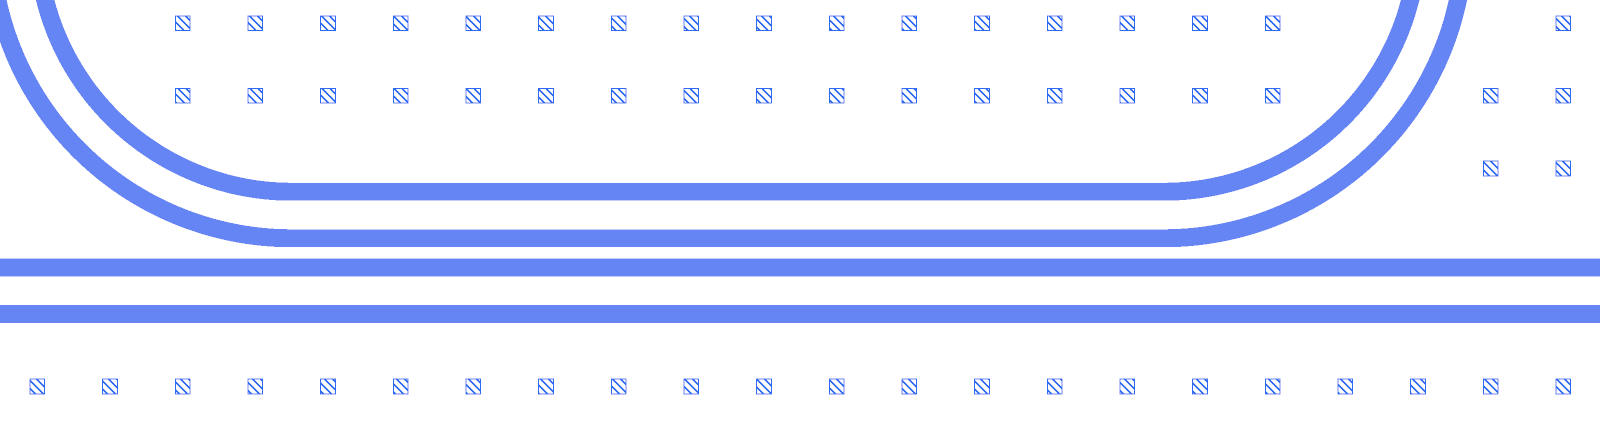

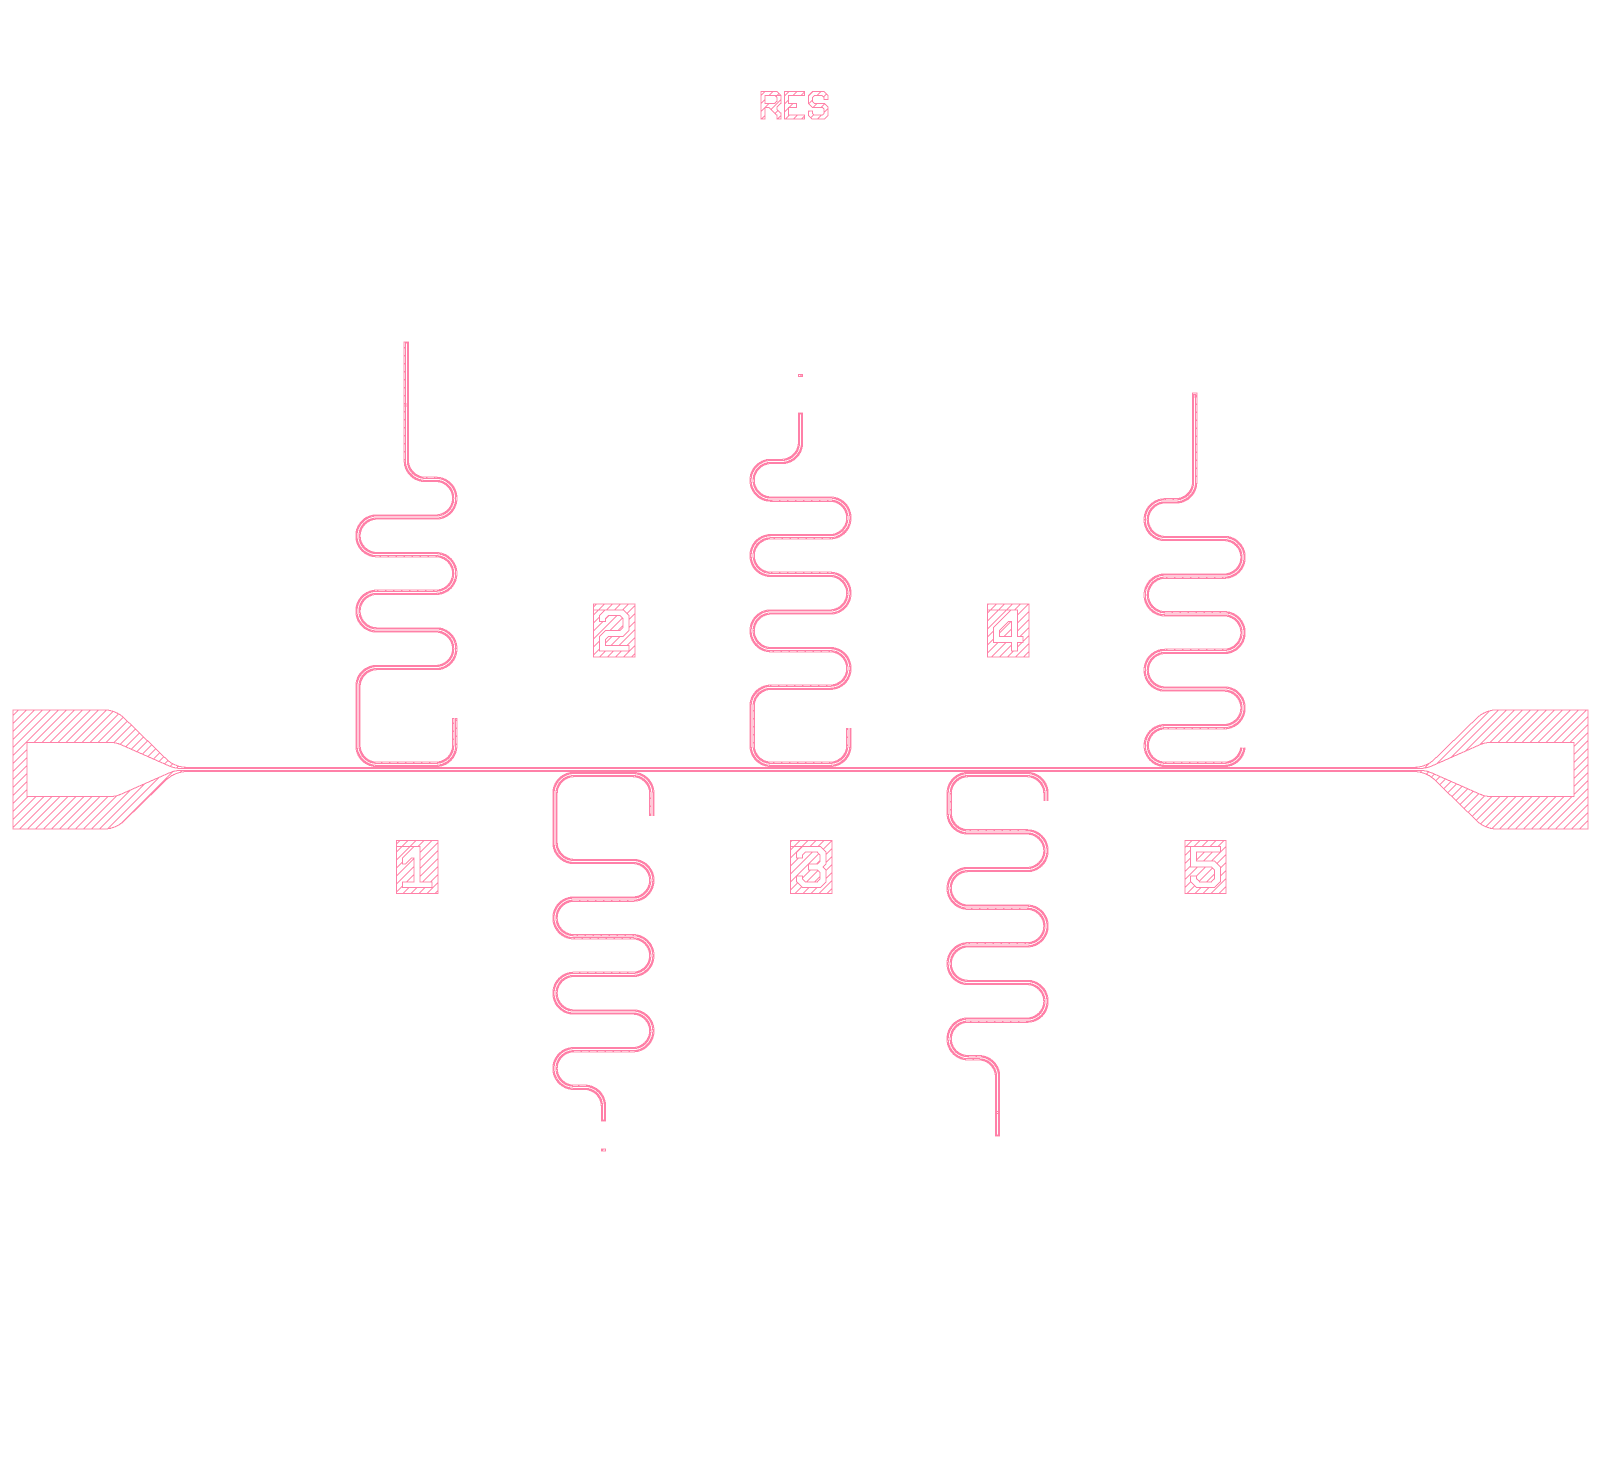

**XOR against the legacy as drawn** (pads at the legacy tips, grounder boxes)

| instance | legacy etch (µm²) | rebuilt etch (µm²) | XOR (µm²) | XOR / legacy |
|---|---|---|---|---|
| FL | 71400 | 67836 | 3564.2 | 4.99% |
| PL | 244550 | 228491 | 303328.9 | 124.04% |
| PR | 244550 | 228491 | 303328.9 | 124.04% |
| R1 | 60076 | 59976 | 100.0 | 0.17% |
| R2 | 59975 | 59975 | 0.0 | 0.00% |
| R3 | 59975 | 59975 | 0.0 | 0.00% |
| R4 | 60075 | 59975 | 100.0 | 0.17% |
| R5 | 60075 | 59975 | 100.0 | 0.17% |
| G1 | 220 | 120 | 100.0 | 45.45% |
| G2 | 220 | 0 | 220.0 | 100.00% |
| G3 | 220 | 0 | 220.0 | 100.00% |
| G4 | 220 | 120 | 100.0 | 45.45% |
| G5 | 220 | 120 | 100.0 | 45.45% |
| LBL_RES | 22400 | 22400 | 0.0 | 0.00% |
| LBL_1 | 44100 | 44100 | 0.0 | 0.00% |
| LBL_2 | 40050 | 40050 | 0.0 | 0.00% |
| LBL_3 | 40950 | 40950 | 0.0 | 0.00% |
| LBL_4 | 42188 | 42188 | 0.0 | 0.00% |
| LBL_5 | 39712 | 39712 | 0.0 | 0.00% |

**XOR with the pads moved 345 µm inwards (PDK pad rule), no grounders**

| instance | legacy etch (µm²) | rebuilt etch (µm²) | XOR (µm²) | XOR / legacy |
|---|---|---|---|---|
| FL | 63120 | 63120 | 0.0 | 0.00% |
| PL | 244550 | 244550 | 0.0 | 0.00% |
| PR | 244550 | 244550 | 0.0 | 0.00% |
| R1 | 59976 | 59976 | 0.0 | 0.00% |
| R2 | 59975 | 59975 | 0.0 | 0.00% |
| R3 | 59975 | 59975 | 0.0 | 0.00% |
| R4 | 59975 | 59975 | 0.0 | 0.00% |
| R5 | 59975 | 59975 | 0.0 | 0.00% |
| LBL_RES | 22400 | 22400 | 0.0 | 0.00% |
| LBL_1 | 44100 | 44100 | 0.0 | 0.00% |
| LBL_2 | 40050 | 40050 | 0.0 | 0.00% |
| LBL_3 | 40950 | 40950 | 0.0 | 0.00% |
| LBL_4 | 42188 | 42188 | 0.0 | 0.00% |
| LBL_5 | 39712 | 39712 | 0.0 | 0.00% |

max XOR (intended chip): 0.0 µm²


In [15]:
X1, Y1 = C.port_xy(d, "R1.end")
XC = C.port_xy(d, "FL.a")[1]                     # feedline y after centring
C.show_snapshot(d, OUT / f"{ID}.png", box=(0, 0, 7500, 7500), size=(1600, 1600))
C.show_snapshot(d, OUT / f"{ID}_r1end.png", box=(X1 - 120, Y1 - 140, X1 + 120, Y1 + 100), size=(800, 800), width=320)
C.show_snapshot(d, OUT / f"{ID}_coupler.png", box=(1500, XC - 50, 2050, XC + 100), size=(1600, 436), width=640)  # R1 coupler
if L.legacy_available():
    from quantcore_circuits.live.snapshot import snapshot
    ref = L.shift_reference(LB.resonator_chip01_reference(), *SHIFT)
    snapshot(ref.write("build/legacy_b/resonator_chip_01_legacy.oas"), OUT / f"{ID}_legacy.png",
             box=(-300, 0, 7800, 7500), size=(1600, 1478))
    display(Image(filename=str(OUT / f"{ID}_legacy.png"), width=640))
    table, xor = L.xor_table(d, ref)
    display(Markdown("**XOR against the legacy as drawn** (pads at the legacy tips, grounder boxes)\n\n" + table))
    table, xor = L.xor_table(d, L.shift_reference(LB.resonator_chip01_reference(pad_shift=PAD_SHIFT, grounders=False), *SHIFT))
    display(Markdown(f"**XOR with the pads moved {PAD_SHIFT:g} µm inwards (PDK pad rule), no grounders**\n\n" + table))
    print("max XOR (intended chip):", round(max(xor.values()), 1), "µm²")
else:
    print("components/ (legacy library) not present: no legacy reference")

## 15 · Summary

- **Matches the source:** the five resonators, the labels, and the pads and feedline at the PDK pad position (XOR
  0 against the intended legacy chip).
- **Differs, by the PDK:** pads `pad_edge` = 100 µm from the die edge (feedline 5260 µm), the circuit centred (−155 µm in y),
  the PDK frame and device ID; the PDK cheese band (the source had none).
- **By design decisions:** no grounder boxes (#13), so the five resonators are degenerate (≈ 6.26 GHz, κ ≈
  0.34 MHz each); spreading their lengths is open (design decision).
- No PDK design warnings.